In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

sys.path.append("../..")
from src.data.dataset_utils import exclude_boundary_nodes
from src.utils.plot_functions import plot_overall_scores, plot_binned_scores, plot_spatial_grids, spatial_grid_from_dataarray

VARIABLE = "sigWaveHeight"  # significant wave height

PREDICT_FINAL_DIR = Path("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_final")
GROUND_TRUTH_ZARR = "/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr"
BOUNDARY_NODES_CSV = "../../src/data/node_selection/boundary_nodes.csv"

# produced by notebooks/paper-plots/compute_experiment_metrics.py
METRICS_DIR = Path("metrics")

CHUNKS = "auto"  # keep everything dask-backed/lazy; set to None to load eagerly

In [ ]:
PAPER_WIDE = (7.1, 3.5)

In [ ]:
def parse_bin_column(bin_series: pd.Series) -> pd.Series:
    """Turn the 'bin' column of a binned-metrics CSV back into pd.Interval objects.

    compute_binned_scores/compute_binned_change_scores return 'bin' as a pd.Interval
    (or the string 'overall'), which round-trips through CSV as a plain string like
    '(0.0, 0.5]'. plot_binned_scores expects real pd.Interval objects (for .mid), so
    we parse them back here after loading the CSV.
    """

    def _parse(value):
        if value == "overall":
            return value
        left, right = value.strip("()[]").split(", ")
        return pd.Interval(float(left), float(right), closed="right")

    return bin_series.apply(_parse)

## RMSE

### Global

In [ ]:
summary_df = pd.read_csv(METRICS_DIR / "summary_metrics.csv")
summary_df.round(decimals=4)

,experiment,total_rmse,total_bias,summer_rmse,summer_bias,winter_rmse,winter_bias
0,swh-gat-250,0.0446,0.0065,0.0369,-0.0088,0.0513,0.0223
1,swh-gat-50,0.0580,0.0169,0.0348,-0.0013,0.0748,0.0358
2,swh-gat-500,0.0630,0.0188,0.0329,-0.0028,0.0833,0.0412
3,swh-gat-lstm-vn-48-250,0.0230,0.0030,0.0171,-0.0015,0.0278,0.0077
4,swh-gat-lstm-vn-48-50,0.0230,-0.0017,0.0176,-0.0040,0.0274,0.0007
5,swh-gat-lstm-vn-48-500,0.0252,0.0005,0.0185,-0.0039,0.0306,0.0051
6,swh-gat-lstm-vn-6-250,0.0205,0.0029,0.0177,0.0008,0.0230,0.0050
7,swh-gat-lstm-vn-6-50,0.0201,0.0012,0.0172,-0.0001,0.0227,0.0024
8,swh-gat-lstm-vn-6-500,0.0224,-0.0008,0.0187,-0.0031,0.0257,0.0016
9,swh-gat-vn-250,0.0425,0.0101,0.0309,-0.0006,0.0517,0.0213


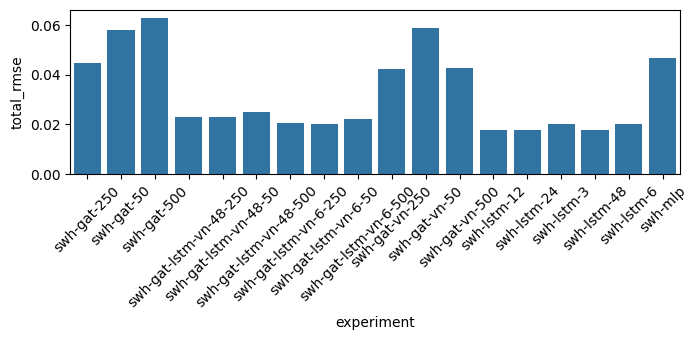

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)
sns.barplot(data=summary_df, x="experiment", y="total_rmse", ax=ax)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

### Summer

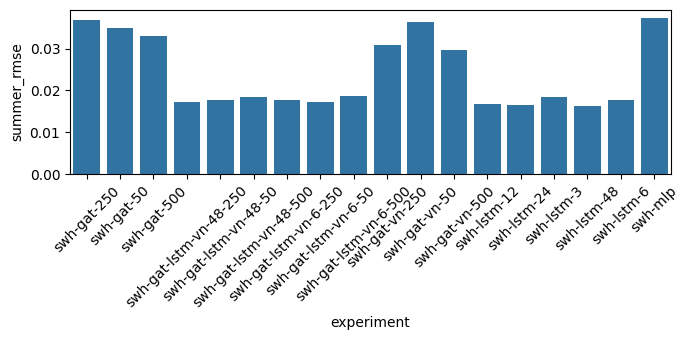

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)
sns.barplot(data=summary_df, x="experiment", y="summer_rmse", ax=ax)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

### Winter

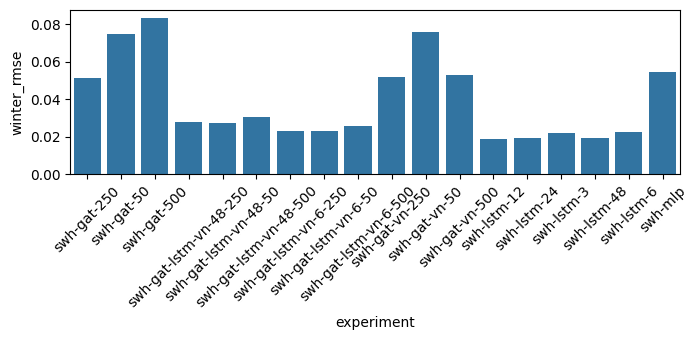

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)
sns.barplot(data=summary_df, x="experiment", y="winter_rmse", ax=ax)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

### Bias

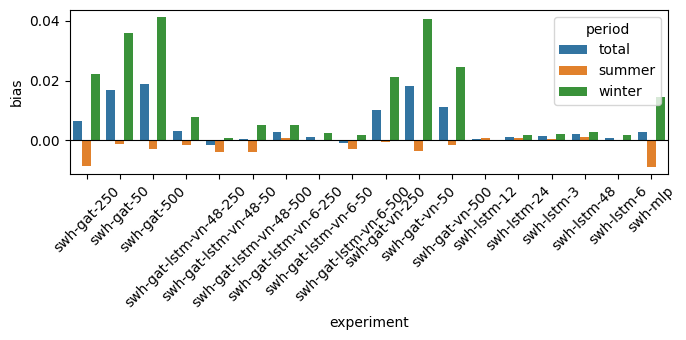

In [ ]:
bias_df = summary_df.melt(
    id_vars="experiment",
    value_vars=["total_bias", "summer_bias", "winter_bias"],
    var_name="period",
    value_name="bias",
)
bias_df["period"] = bias_df["period"].str.replace("_bias", "")

fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)
sns.barplot(data=bias_df, x="experiment", y="bias", hue="period", ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

### Binned by value

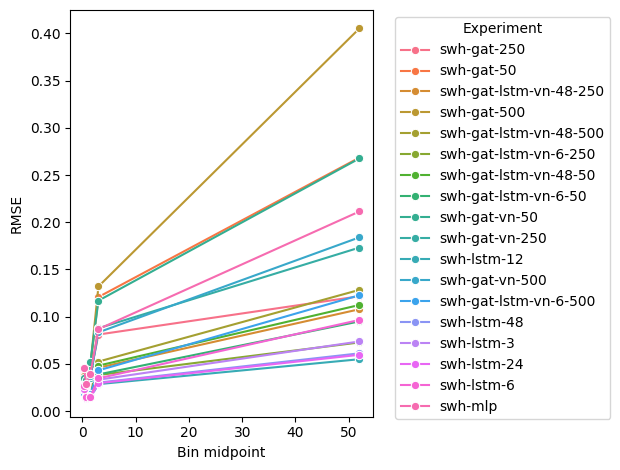

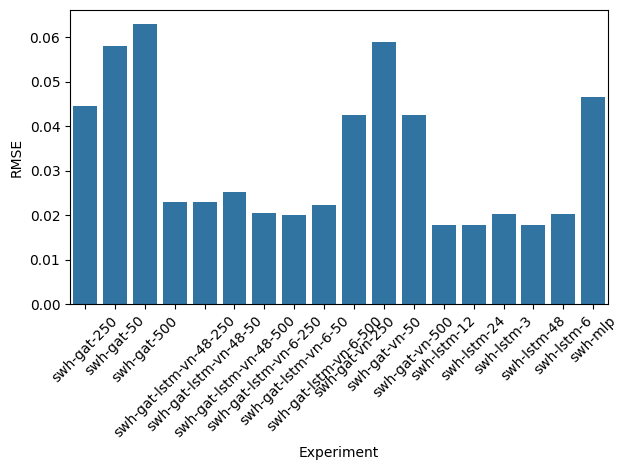

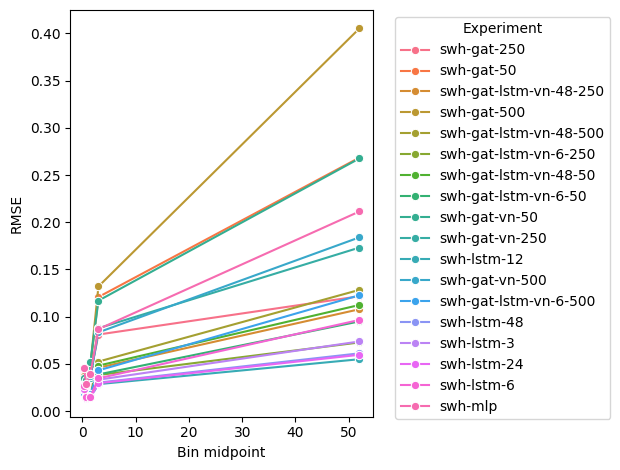

In [ ]:
binned_value_df = pd.read_csv(METRICS_DIR / "binned_value_metrics.csv")
binned_value_df["bin"] = parse_bin_column(binned_value_df["bin"])

plot_overall_scores(binned_value_df, metric="rmse")
plot_binned_scores(binned_value_df, metric="rmse")

### Binned by change

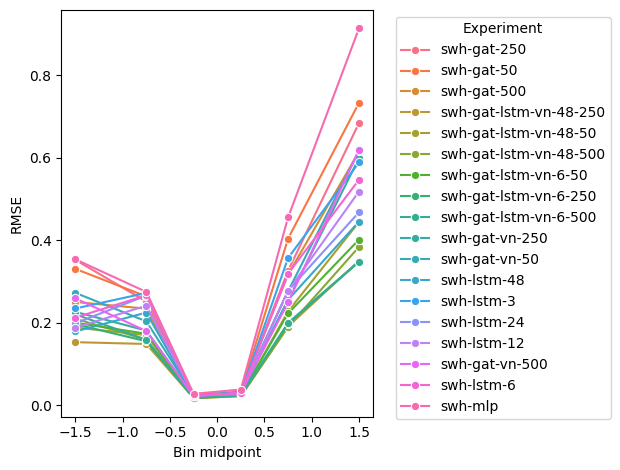

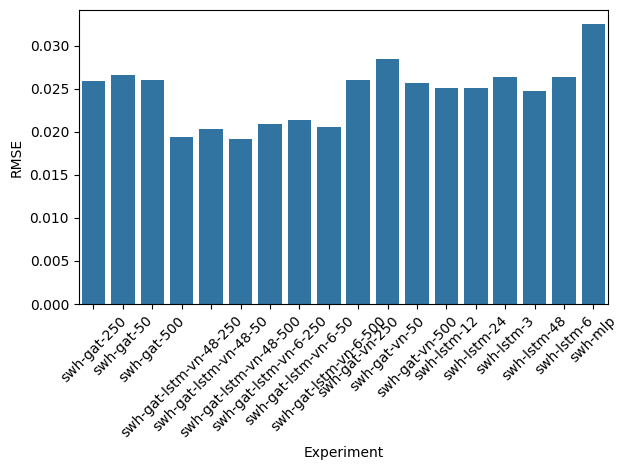

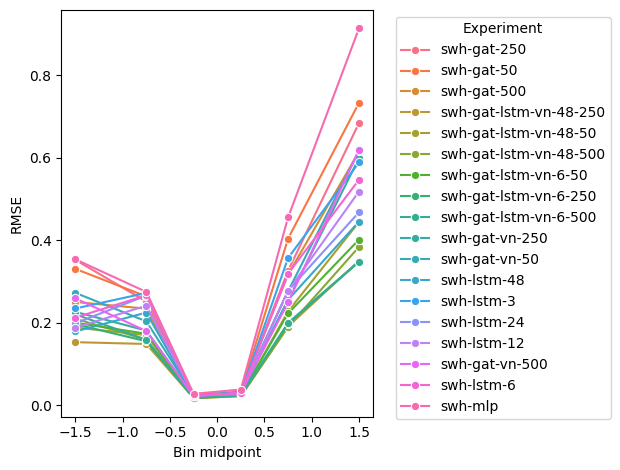

In [ ]:
binned_change_df = pd.read_csv(METRICS_DIR / "binned_change_metrics.csv")
binned_change_df["bin"] = parse_bin_column(binned_change_df["bin"])

plot_overall_scores(binned_change_df, metric="rmse")
plot_binned_scores(binned_change_df, metric="rmse")

## Selected experiments only

In [ ]:
keep_experiments = ["swh-mlp", "swh-lstm-12", "swh-gat-500", "swh-gat-vn-500", "swh-gat-lstm-vn-6-50", "swh-gat-lstm-vn-6-500"]

In [ ]:
# define architecture priority for sorting
arch_priority = {
    "mlp": 0,
    "lstm": 1,
    "gat": 2,        # Graph (must check before gat-vn / gat-lstm-vn, see note below)
    "gat-vn": 3,      # Graph-VN
    "gat-lstm-vn": 4, # Graph-LSTM
}

def get_arch_key(experiment):
    # order matters: check longest/most-specific patterns first
    if "gat-lstm-vn" in experiment:
        return arch_priority["gat-lstm-vn"]
    if "gat-vn" in experiment:
        return arch_priority["gat-vn"]
    if "gat" in experiment:
        return arch_priority["gat"]
    if "lstm" in experiment:
        return arch_priority["lstm"]
    if "mlp" in experiment:
        return arch_priority["mlp"]
    return 99  # fallback, shouldn't hit if keep_experiments is well-formed

hue_order = sorted(keep_experiments, key=get_arch_key)

new_labels = ["MLP", "LSTM (sl=12)", "Graph (w/o VN) (n=500)", "Graph (n=500)", "GraphLSTM (sl=6, n=50)", "GraphLSTM (sl=6, n=500)"]

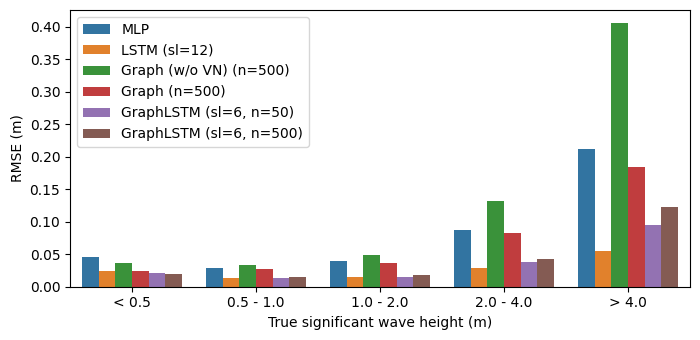

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)

sns.barplot(binned_value_df.query("experiment in @keep_experiments").query("bin != 'overall'"),
            x="bin", y="rmse", hue="experiment", hue_order=hue_order)

ax.set_xlabel("True significant wave height (m)")
ax.set_ylabel("RMSE (m)")

ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(["< 0.5", "0.5 - 1.0", "1.0 - 2.0", "2.0 - 4.0", "> 4.0"])

handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, new_labels)

fig.tight_layout()

plt.savefig("rmse_swh_per_swh_bin.png", dpi=200)

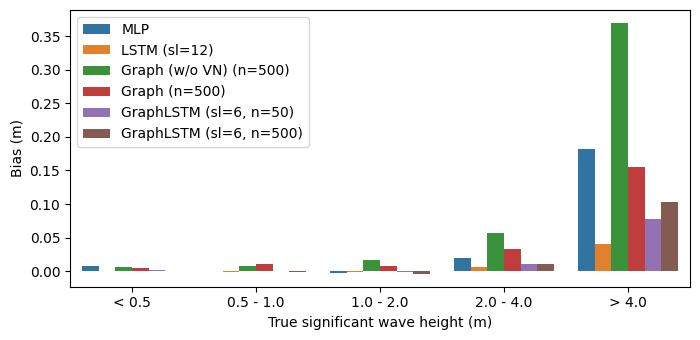

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)

sns.barplot(binned_value_df.query("experiment in @keep_experiments").query("bin != 'overall'"),
            x="bin", y="bias", hue="experiment", hue_order=hue_order)

ax.set_xlabel("True significant wave height (m)")
ax.set_ylabel("Bias (m)")

ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(["< 0.5", "0.5 - 1.0", "1.0 - 2.0", "2.0 - 4.0", "> 4.0"])

handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, new_labels)

fig.tight_layout()

plt.savefig("bias_swh_per_swh_bin.png", dpi=200)

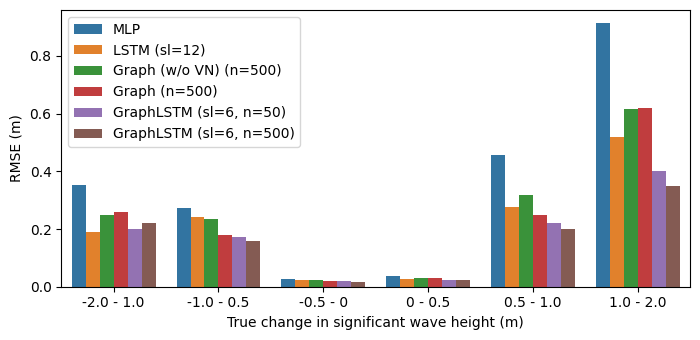

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)

sns.barplot(binned_change_df.query("experiment in @keep_experiments").query("bin != 'overall'"),
            x="bin", y="rmse", hue="experiment", hue_order=hue_order)

ax.set_xlabel("True change in significant wave height (m)")
ax.set_ylabel("RMSE (m)")

ax.set_xticks([0, 1, 2, 3, 4, 5])
ax.set_xticklabels(["-2.0 - 1.0", "-1.0 - 0.5", "-0.5 - 0", "0 - 0.5", "0.5 - 1.0", "1.0 - 2.0"])


handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, new_labels)

fig.tight_layout()

plt.savefig("rmse_swh_per_dswh_bin.png", dpi=200)

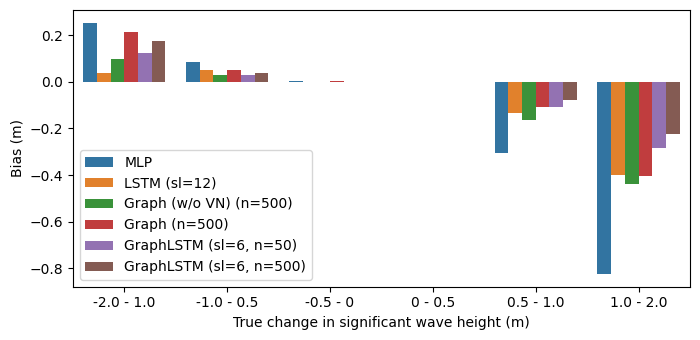

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_WIDE)

sns.barplot(binned_change_df.query("experiment in @keep_experiments").query("bin != 'overall'"),
            x="bin", y="bias", hue="experiment", hue_order=hue_order)

ax.set_xlabel("True change in significant wave height (m)")
ax.set_ylabel("Bias (m)")

ax.set_xticks([0, 1, 2, 3, 4, 5])
ax.set_xticklabels(["-2.0 - 1.0", "-1.0 - 0.5", "-0.5 - 0", "0 - 0.5", "0.5 - 1.0", "1.0 - 2.0"])


handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, new_labels)

fig.tight_layout()

plt.savefig("bias_swh_per_dswh_bin.png", dpi=200)

## Spatial analysis

In [ ]:
skeys = ["mlp", "lstm-6", "gat-vn-50", "gat-lstm-vn-6-50"]
sdict = {}

for key in skeys:
    print(key)
    sdict[key] = xr.open_dataset(f"./spatial_metrics/swh-{key}_spatial_metrics.nc")

mlp
lstm-6
gat-vn-50
gat-lstm-vn-6-50


In [ ]:
grids = {key: spatial_grid_from_dataarray(sdict[key].sel(season="winter")["rmse"]) for key in skeys}

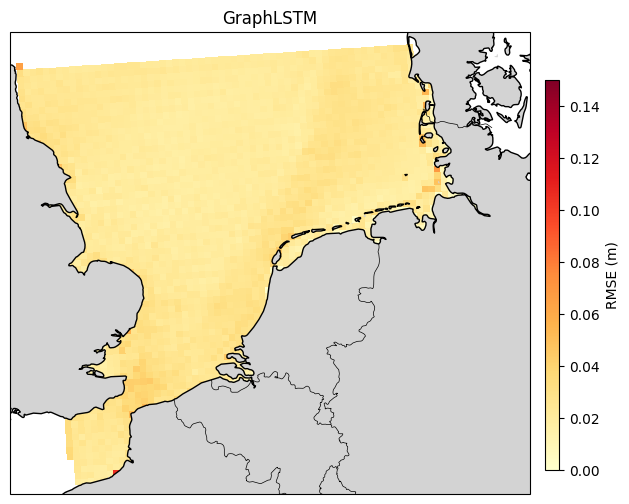

In [ ]:
fig = plot_spatial_grids({"GraphLSTM":grids["gat-lstm-vn-6-50"]}, title="", cbar_label="RMSE (m)", vmin=0, vmax=0.15)

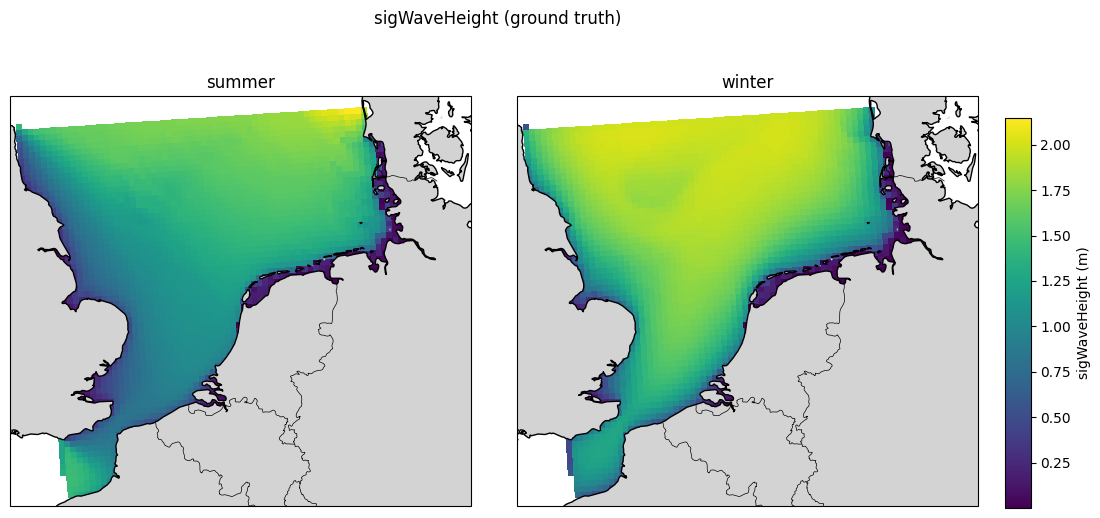

In [ ]:
# ground truth maps: swap "rmse" for "ground_truth_mean" and use a different cmap/vmin/vmax
gt_grids = {
    "summer": spatial_grid_from_dataarray(sdict["mlp"]["ground_truth_mean"].sel(season="summer")),
    "winter": spatial_grid_from_dataarray(sdict["mlp"]["ground_truth_mean"].sel(season="winter")),
}
fig2 = plot_spatial_grids(gt_grids, title="sigWaveHeight (ground truth)", cbar_label="sigWaveHeight (m)", cmap="viridis")

## Rollout

In [ ]:
rmetrics = {
    "mlp": pd.read_csv("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/rollout/runs/2026-09-09_13-20-32/rollout_metrics_lead.csv")[["lead", "rmse_sigWaveHeight"]],
    "lstm": pd.read_csv("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/rollout/runs/2026-09-09_12-45-07/rollout_metrics_lead.csv")[["lead", "rmse_sigWaveHeight"]], # LSTM 6
    "graph": pd.read_csv("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/rollout/runs/2026-09-09_12-32-00/rollout_metrics_lead.csv")[["lead", "rmse_sigWaveHeight"]], # Graph 50
    "graphlstm":pd.read_csv("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/rollout/runs/2026-09-09_12-18-58/rollout_metrics_lead.csv")[["lead", "rmse_sigWaveHeight"]], # LSTM 6 50
}

for k,v in rmetrics.items():
    v["experiment"] = k

rmetrics = pd.concat(rmetrics)
rmetrics

lead  rmse_sigWaveHeight experiment
mlp       0      1            0.087264        mlp
          1      2            0.174987        mlp
          2      3            0.207713        mlp
          3      4            0.239492        mlp
          4      5            0.401310        mlp
...            ...                 ...        ...
graphlstm 67    68            0.209870  graphlstm
          68    69            0.232249  graphlstm
          69    70            0.255735  graphlstm
          70    71            0.280232  graphlstm
          71    72            0.290153  graphlstm

[288 rows x 3 columns]

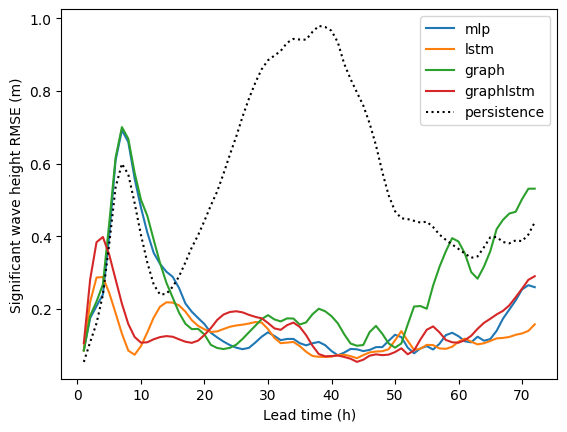

In [ ]:
fig, ax = plt.subplots(1, 1)

sns.lineplot(data=rmetrics, x="lead", y="rmse_sigWaveHeight", hue="experiment")

persist = pd.read_csv("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/rollout/runs/2026-09-09_13-20-32/rollout_metrics_lead.csv")
sns.lineplot(data=persist, x="lead", y="rmse_persistence_sigWaveHeight", color="k", ls=":", label="persistence")


ax.legend()
ax.set_xlabel("Lead time (h)")
ax.set_ylabel("Significant wave height RMSE (m)")
plt.show()

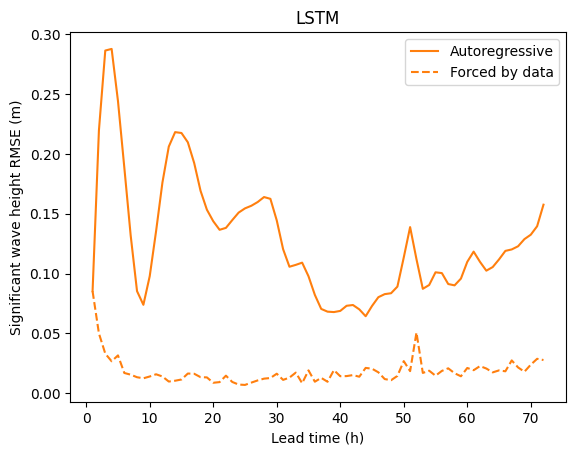

In [ ]:
teacher = pd.read_csv("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/rollout/runs/2026-09-09_13-26-01/rollout_metrics_lead.csv")
sns.lineplot(data=teacher, x="lead", y="rmse_sigWaveHeight", color="C1", label="Autoregressive")
sns.lineplot(data=teacher, x="lead", y="rmse_teacher_forced_sigWaveHeight", color="C1", ls="--", label="Forced by data")
plt.legend()
plt.title("LSTM")

plt.xlabel("Lead time (h)")
plt.ylabel("Significant wave height RMSE (m)")
plt.show()

In [ ]:
## tmp

In [ ]:
true = xr.open_dataset("/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr")

In [ ]:
true = true.isel(nSCHISM_hgrid_node=slice(None, None, 100000))

In [ ]:
true

<xarray.Dataset> Size: 287GB
Dimensions:                  (time: 8760, nSCHISM_hgrid_node: 6,
                              nSCHISM_hgrid_edge: 1758191, two: 2,
                              nSCHISM_hgrid_face: 1168634,
                              nMaxSCHISM_hgrid_face_nodes: 4)
Coordinates:
  * time                     (time) datetime64[ns] 70kB 2020-01-01T01:00:00 ....
    SCHISM_hgrid_node_x      (nSCHISM_hgrid_node) float32 24B ...
    SCHISM_hgrid_node_y      (nSCHISM_hgrid_node) float32 24B ...
    SCHISM_hgrid_edge_x      (nSCHISM_hgrid_edge) float32 7MB ...
    SCHISM_hgrid_edge_y      (nSCHISM_hgrid_edge) float32 7MB ...
    SCHISM_hgrid_face_x      (nSCHISM_hgrid_face) float32 5MB ...
    SCHISM_hgrid_face_y      (nSCHISM_hgrid_face) float32 5MB ...
Dimensions without coordinates: nSCHISM_hgrid_node, nSCHISM_hgrid_edge, two,
                                nSCHISM_hgrid_face, nMaxSCHISM_hgrid_face_nodes
Data variables: (12/16)
    depthAverageVelX         (time, nSCHISM_hgrid_node) float32 210kB ...
    depthAverageVelY         (time, nSCHISM_hgrid_node) float32 210kB ...
    dryFlagNode              (time, nSCHISM_hgrid_node) float32 210kB ...
    elevation                (time, nSCHISM_hgrid_node) float32 210kB ...
    meanDirSpreading         (time, nSCHISM_hgrid_node) float32 210kB ...
    meanWaveDirection        (time, nSCHISM_hgrid_node) float32 210kB ...
    ...                       ...
    SCHISM_hgrid_edge_nodes  (time, nSCHISM_hgrid_edge, two) float32 123GB ...
    SCHISM_hgrid_face_nodes  (time, nSCHISM_hgrid_face, nMaxSCHISM_hgrid_face_nodes) float32 164GB ...
    sigWaveHeight            (time, nSCHISM_hgrid_node) float32 210kB ...
    TM10                     (time, nSCHISM_hgrid_node) float32 210kB ...
    windSpeedX               (time, nSCHISM_hgrid_node) float32 210kB ...
    windSpeedY               (time, nSCHISM_hgrid_node) float32 210kB ...

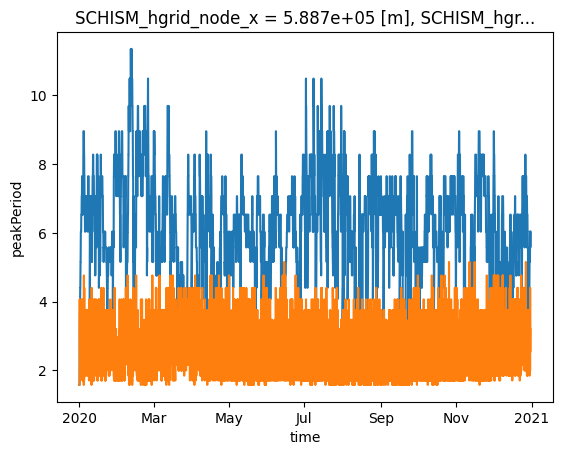

In [ ]:
true["peakPeriod"].isel(nSCHISM_hgrid_node=2).plot()
true["peakPeriod"].isel(nSCHISM_hgrid_node=0).plot()

In [ ]:
pp = true["peakPeriod"].isel(nSCHISM_hgrid_node=2).values
sw = true["sigWaveHeight"].isel(nSCHISM_hgrid_node=2).values

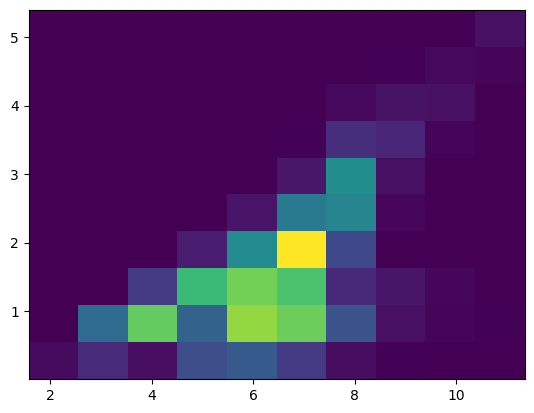

In [ ]:
plt.hist2d(pp, sw);